In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_excel("Tomorrow Syndrome.xlsx")

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

Saving Tomorrow Syndrome.xlsx to Tomorrow Syndrome.xlsx
Dataset loaded successfully
Shape: (107, 14)


,Timestamp,What is your age group?,What is your current CGPA / academic performance level?,How many hours per day do you use your mobile phone for non-academic purposes?,Time Lost to Procrastination,What social media platform do you use most often?,How long do you usually postpone an academic task after deciding to do it?,How long before an examination do you usually start preparing seriously?,How often do you prepare and follow a study timetable or schedule?,"When you delay an academic task, what is the main reason?","How often do you tell yourself, “I’ll do it later” or “I’ll do it tomorrow” for academic work?","When you procrastinate on academic work, how do you usually feel?","On a scale of 1 to 5, how frequently do social or emotional relationship factors (e.g., hanging out with friends, messaging/talking to romantic partners, or family stress/conflict) cause you to delay your academic tasks?",What is the primary way your social or emotional relationships lead to procrastination?
0,2026-10-05 21:25:29.185,17-19,9 above,1-2 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Sometimes,Guilty,3.0,FOMO / Social pressure (Fear of missing out on...
1,2026-10-05 21:26:28.659,17-19,9 above,2-4 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,The task feels difficult,Sometimes,Stressed,2.0,No effect (Relationships don't affect my study...
2,2026-10-05 21:26:50.357,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,1-3 days,The day before,Rarely,I feel tired or the task is boring,Very Often,Guilty,3.0,No effect (Relationships don't affect my study...
3,2026-10-05 21:27:41.237,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,Less than 1 day,The day before,Often,I have too much work,Very Often,Stressed,4.0,No effect (Relationships don't affect my study...
4,2026-10-05 21:30:30.371,17-19,7-7.9,More than 4 hours,5+hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Very Often,Stressed,3.0,"Emotional stress (Arguments, family issues, re..."


In [ ]:
df.columns = [
    "timestamp",
    "age_group",
    "academic_performance",
    "phone_usage",
    "procrastination_time",
    "social_media",
    "postpone_duration",
    "exam_preparation",
    "schedule_frequency",
    "delay_reason",
    "tomorrow_frequency",
    "feeling_after_procrastination",
    "social_emotional_score",
    "social_emotional_reason"
]

print(df.columns)
df.head()

Index(['timestamp', 'age_group', 'academic_performance', 'phone_usage',
       'procrastination_time', 'social_media', 'postpone_duration',
       'exam_preparation', 'schedule_frequency', 'delay_reason',
       'tomorrow_frequency', 'feeling_after_procrastination',
       'social_emotional_score', 'social_emotional_reason'],
      dtype='object')


,timestamp,age_group,academic_performance,phone_usage,procrastination_time,social_media,postpone_duration,exam_preparation,schedule_frequency,delay_reason,tomorrow_frequency,feeling_after_procrastination,social_emotional_score,social_emotional_reason
0,2026-10-05 21:25:29.185,17-19,9 above,1-2 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Sometimes,Guilty,3.0,FOMO / Social pressure (Fear of missing out on...
1,2026-10-05 21:26:28.659,17-19,9 above,2-4 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,The task feels difficult,Sometimes,Stressed,2.0,No effect (Relationships don't affect my study...
2,2026-10-05 21:26:50.357,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,1-3 days,The day before,Rarely,I feel tired or the task is boring,Very Often,Guilty,3.0,No effect (Relationships don't affect my study...
3,2026-10-05 21:27:41.237,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,Less than 1 day,The day before,Often,I have too much work,Very Often,Stressed,4.0,No effect (Relationships don't affect my study...
4,2026-10-05 21:30:30.371,17-19,7-7.9,More than 4 hours,5+hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Very Often,Stressed,3.0,"Emotional stress (Arguments, family issues, re..."


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (107, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   timestamp                      107 non-null    datetime64[ns]
 1   age_group                      106 non-null    object        
 2   academic_performance           106 non-null    object        
 3   phone_usage                    106 non-null    object        
 4   procrastination_time           106 non-null    object        
 5   social_media                   106 non-null    object        
 6   postpone_duration              106 non-null    object        
 7   exam_preparation               106 non-null    object        
 8   schedule_frequency             106 non-null    object        
 9   delay_reason                   105 non-null    object        
 10  tomorrow_frequency             105 non-

In [ ]:
import numpy as np
import pandas as pd

df = df.drop_duplicates()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["response_date"] = df["timestamp"].dt.date
df["response_hour"] = df["timestamp"].dt.hour

print("Cleaning completed")
df.head()

Cleaning completed


,timestamp,age_group,academic_performance,phone_usage,procrastination_time,social_media,postpone_duration,exam_preparation,schedule_frequency,delay_reason,tomorrow_frequency,feeling_after_procrastination,social_emotional_score,social_emotional_reason,response_date,response_hour
0,2026-10-05 21:25:29.185,17-19,9 above,1-2 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Sometimes,Guilty,3.0,FOMO / Social pressure (Fear of missing out on...,2026-10-05,21
1,2026-10-05 21:26:28.659,17-19,9 above,2-4 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,The task feels difficult,Sometimes,Stressed,2.0,No effect (Relationships don't affect my study...,2026-10-05,21
2,2026-10-05 21:26:50.357,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,1-3 days,The day before,Rarely,I feel tired or the task is boring,Very Often,Guilty,3.0,No effect (Relationships don't affect my study...,2026-10-05,21
3,2026-10-05 21:27:41.237,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,Less than 1 day,The day before,Often,I have too much work,Very Often,Stressed,4.0,No effect (Relationships don't affect my study...,2026-10-05,21
4,2026-10-05 21:30:30.371,17-19,7-7.9,More than 4 hours,5+hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,Very Often,Stressed,3.0,"Emotional stress (Arguments, family issues, re...",2026-10-05,21


In [ ]:
categorical_columns = [
    "age_group",
    "academic_performance",
    "phone_usage",
    "procrastination_time",
    "social_media",
    "postpone_duration",
    "exam_preparation",
    "schedule_frequency",
    "delay_reason",
    "tomorrow_frequency",
    "feeling_after_procrastination",
    "social_emotional_reason"
]

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

df["social_emotional_score"] = pd.to_numeric(
    df["social_emotional_score"],
    errors="coerce"
)

df["social_emotional_score"] = (
    df["social_emotional_score"]
    .fillna(df["social_emotional_score"].median())
)

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
timestamp                        0
age_group                        0
academic_performance             0
phone_usage                      0
procrastination_time             0
social_media                     0
postpone_duration                0
exam_preparation                 0
schedule_frequency               0
delay_reason                     0
tomorrow_frequency               0
feeling_after_procrastination    0
social_emotional_score           0
social_emotional_reason          0
response_date                    0
response_hour                    0
dtype: int64


In [ ]:
columns_to_check = [
    "age_group",
    "academic_performance",
    "phone_usage",
    "procrastination_time",
    "social_media",
    "postpone_duration",
    "exam_preparation",
    "schedule_frequency",
    "delay_reason",
    "tomorrow_frequency",
    "feeling_after_procrastination",
    "social_emotional_score",
    "social_emotional_reason"
]

for col in columns_to_check:
    print("\n", "=" * 50)
    print(col.upper())
    print("=" * 50)
    print(df[col].value_counts(dropna=False))


AGE_GROUP
age_group
17-19       65
Above 25    20
20-22       15
23-25        6
Unknown      1
Name: count, dtype: int64

ACADEMIC_PERFORMANCE
academic_performance
8-8.9      56
9 above    23
7-7.9      21
6-6.9       6
Unknown     1
Name: count, dtype: int64

PHONE_USAGE
phone_usage
More than 4 hours    37
2-4 hours            35
1-2 hours            23
Less than 1 hour     11
Unknown               1
Name: count, dtype: int64

PROCRASTINATION_TIME
procrastination_time
1-2 hours           38
3-4 hours           29
5+hours             21
less than 1 hour    18
Unknown              1
Name: count, dtype: int64

SOCIAL_MEDIA
social_media
Instagram                               45
Instagram, Whatsapp                     17
Youtube                                 11
Whatsapp                                10
Instagram, Whatsapp, Youtube, Others     7
Others                                   4
Instagram, Whatsapp, Youtube             4
Instagram, Youtube                       4
Whatsapp, You

In [ ]:
age_mapping = {
    "17-19": 1,
    "20-22": 2,
    "23-25": 3,
    "Above 25": 4
}

performance_mapping = {
    "6-6.9": 6.5,
    "7-7.9": 7.5,
    "8-8.9": 8.5,
    "9 above": 9.5
}

phone_mapping = {
    "Less than 1 hour": 0.5,
    "1-2 hours": 1.5,
    "2-4 hours": 3.0,
    "More than 4 hours": 5.0
}

procrastination_mapping = {
    "less than 1 hour": 0.5,
    "1-2 hours": 1.5,
    "3-4 hours": 3.5,
    "5+hours": 5.0
}

df["age_encoded"] = df["age_group"].map(age_mapping)

df["cgpa_numeric"] = (
    df["academic_performance"]
    .map(performance_mapping)
)

df["phone_hours"] = (
    df["phone_usage"]
    .map(phone_mapping)
)

df["procrastination_hours"] = (
    df["procrastination_time"]
    .map(procrastination_mapping)
)

df[
    [
        "age_encoded",
        "cgpa_numeric",
        "phone_hours",
        "procrastination_hours"
    ]
].head()

,age_encoded,cgpa_numeric,phone_hours,procrastination_hours
0,1.0,9.5,1.5,1.5
1,1.0,9.5,3.0,1.5
2,1.0,8.5,3.0,3.5
3,1.0,8.5,3.0,3.5
4,1.0,7.5,5.0,5.0


In [ ]:
postpone_mapping = {
    "I usually start immediately": 0,
    "Less than 1 day": 1,
    "1-3 days": 2,
    "More than 4 days": 3
}

exam_mapping = {
    "More than 2 weeks before": 0,
    "1-2 weeks before": 1,
    "4-7 days before": 2,
    "The day before": 3
}

schedule_mapping = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Often": 3,
    "Always": 4
}

tomorrow_mapping = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Very Often": 3
}

df["postpone_score"] = (
    df["postpone_duration"]
    .map(postpone_mapping)
)

df["exam_delay_score"] = (
    df["exam_preparation"]
    .map(exam_mapping)
)

df["schedule_score"] = (
    df["schedule_frequency"]
    .map(schedule_mapping)
)

df["schedule_risk"] = 4 - df["schedule_score"]

df["tomorrow_score"] = (
    df["tomorrow_frequency"]
    .map(tomorrow_mapping)
)

df[
    [
        "postpone_score",
        "exam_delay_score",
        "schedule_score",
        "schedule_risk",
        "tomorrow_score"
    ]
].head()

,postpone_score,exam_delay_score,schedule_score,schedule_risk,tomorrow_score
0,2.0,3.0,1.0,3.0,2.0
1,2.0,3.0,1.0,3.0,2.0
2,2.0,3.0,1.0,3.0,3.0
3,1.0,3.0,3.0,1.0,3.0
4,2.0,3.0,1.0,3.0,3.0


In [ ]:
df["uses_instagram"] = (
    df["social_media"]
    .str.contains("Instagram", case=False, na=False)
    .astype(int)
)

df["uses_whatsapp"] = (
    df["social_media"]
    .str.contains("Whatsapp", case=False, na=False)
    .astype(int)
)

df["uses_youtube"] = (
    df["social_media"]
    .str.contains("Youtube", case=False, na=False)
    .astype(int)
)

df["uses_other_social"] = (
    df["social_media"]
    .str.contains("Others", case=False, na=False)
    .astype(int)
)

df[
    [
        "social_media",
        "uses_instagram",
        "uses_whatsapp",
        "uses_youtube",
        "uses_other_social"
    ]
].head()

,social_media,uses_instagram,uses_whatsapp,uses_youtube,uses_other_social
0,Instagram,1,0,0,0
1,Instagram,1,0,0,0
2,Instagram,1,0,0,0
3,Instagram,1,0,0,0
4,Instagram,1,0,0,0


In [ ]:
reason_encoded = pd.get_dummies(
    df["delay_reason"],
    prefix="reason",
    dtype=int
)

feeling_encoded = pd.get_dummies(
    df["feeling_after_procrastination"],
    prefix="feeling",
    dtype=int
)

social_reason_encoded = pd.get_dummies(
    df["social_emotional_reason"],
    prefix="social_reason",
    dtype=int
)

df = pd.concat(
    [
        df,
        reason_encoded,
        feeling_encoded,
        social_reason_encoded
    ],
    axis=1
)

print("Encoding completed")
print("New shape:", df.shape)
df.head()

Encoding completed
New shape: (107, 45)


,timestamp,age_group,academic_performance,phone_usage,procrastination_time,social_media,postpone_duration,exam_preparation,schedule_frequency,delay_reason,...,feeling_Confident that I can finish later,feeling_Guilty,feeling_Stressed,feeling_Unknown,"social_reason_Emotional stress (Arguments, family issues, relationship tension)",social_reason_FOMO / Social pressure (Fear of missing out on plans),"social_reason_Feeling unsupported (Isolation, lack of motivation)",social_reason_No effect (Relationships don't affect my study habits),"social_reason_Social distraction (Hanging out, messaging, socializing)",social_reason_Unknown
0,2026-10-05 21:25:29.185,17-19,9 above,1-2 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,...,0,1,0,0,0,1,0,0,0,0
1,2026-10-05 21:26:28.659,17-19,9 above,2-4 hours,1-2 hours,Instagram,1-3 days,The day before,Rarely,The task feels difficult,...,0,0,1,0,0,0,0,1,0,0
2,2026-10-05 21:26:50.357,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,1-3 days,The day before,Rarely,I feel tired or the task is boring,...,0,1,0,0,0,0,0,1,0,0
3,2026-10-05 21:27:41.237,17-19,8-8.9,2-4 hours,3-4 hours,Instagram,Less than 1 day,The day before,Often,I have too much work,...,0,0,1,0,0,0,0,1,0,0
4,2026-10-05 21:30:30.371,17-19,7-7.9,More than 4 hours,5+hours,Instagram,1-3 days,The day before,Rarely,I get distracted by my phone/social media,...,0,0,1,0,1,0,0,0,0,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

risk_columns = [
    "phone_hours",
    "procrastination_hours",
    "postpone_score",
    "exam_delay_score",
    "schedule_risk",
    "tomorrow_score",
    "social_emotional_score"
]

risk_data = df[risk_columns].copy()

for col in risk_columns:
    risk_data[col] = risk_data[col].fillna(
        risk_data[col].median()
    )

scaler = MinMaxScaler()

scaled_risk = scaler.fit_transform(risk_data)

df["procrastination_risk_score"] = (
    scaled_risk.mean(axis=1) * 100
).round(1)

def risk_category(score):
    if score <= 30:
        return "Low"
    elif score <= 60:
        return "Moderate"
    elif score <= 80:
        return "High"
    else:
        return "Very High"

df["risk_category"] = (
    df["procrastination_risk_score"]
    .apply(risk_category)
)

df[
    [
        "procrastination_risk_score",
        "risk_category"
    ]
].head(10)

,procrastination_risk_score,risk_category
0,61.1,High
1,62.3,High
2,77.0,High
3,66.3,High
4,88.1,Very High
5,67.9,High
6,33.7,Moderate
7,78.6,High
8,56.3,Moderate
9,49.6,Moderate


In [ ]:
columns = [
    "age_group",
    "academic_performance",
    "phone_usage",
    "procrastination_time",
    "postpone_duration",
    "exam_preparation",
    "schedule_frequency",
    "delay_reason",
    "tomorrow_frequency",
    "feeling_after_procrastination",
    "social_emotional_reason"
]

for col in columns:
    print("\n" + "=" * 60)
    print(col.upper())
    print("=" * 60)

    result = (
        df[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
    )

    print(result)


AGE_GROUP
age_group
17-19       60.7
Above 25    18.7
20-22       14.0
23-25        5.6
Unknown      0.9
Name: proportion, dtype: float64

ACADEMIC_PERFORMANCE
academic_performance
8-8.9      52.3
9 above    21.5
7-7.9      19.6
6-6.9       5.6
Unknown     0.9
Name: proportion, dtype: float64

PHONE_USAGE
phone_usage
More than 4 hours    34.6
2-4 hours            32.7
1-2 hours            21.5
Less than 1 hour     10.3
Unknown               0.9
Name: proportion, dtype: float64

PROCRASTINATION_TIME
procrastination_time
1-2 hours           35.5
3-4 hours           27.1
5+hours             19.6
less than 1 hour    16.8
Unknown              0.9
Name: proportion, dtype: float64

POSTPONE_DURATION
postpone_duration
Less than 1 day                39.3
1-3 days                       29.9
I usually start immediately    15.0
More than 4 days               15.0
Unknown                         0.9
Name: proportion, dtype: float64

EXAM_PREPARATION
exam_preparation
The day before              37.

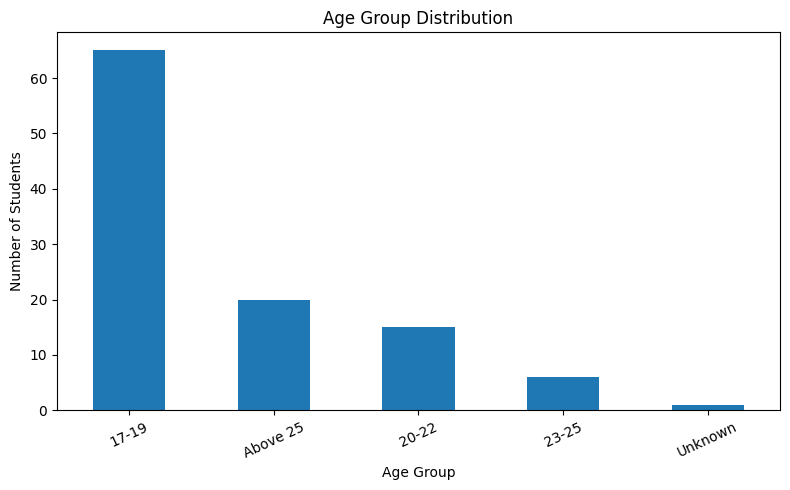

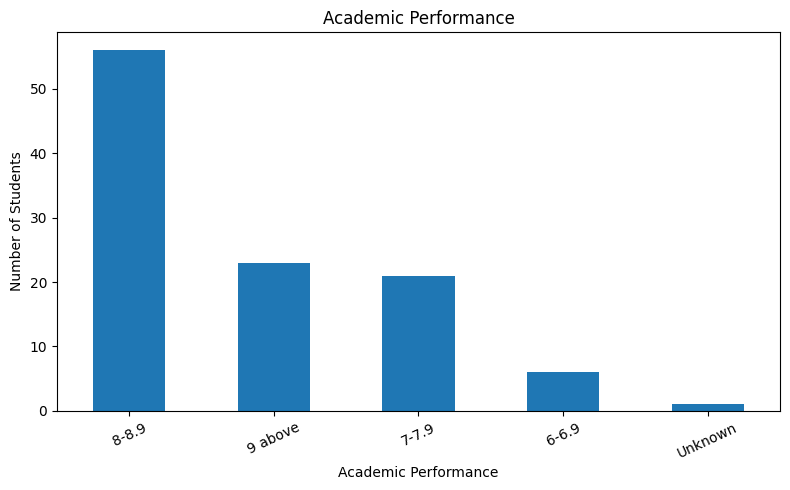

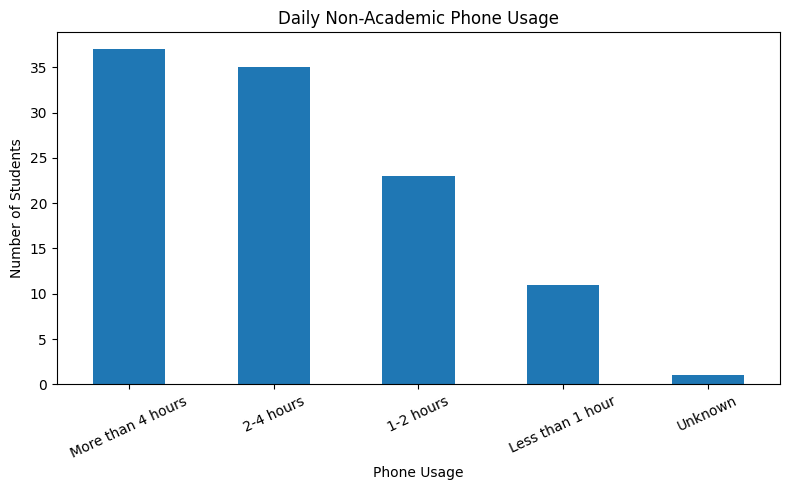

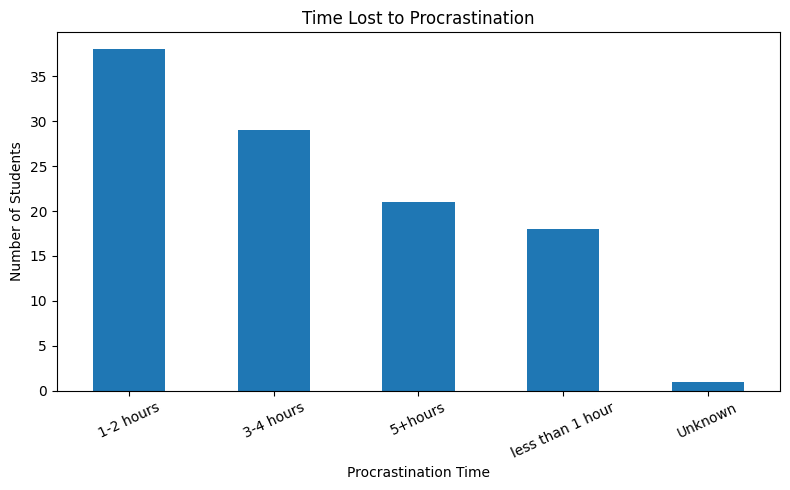

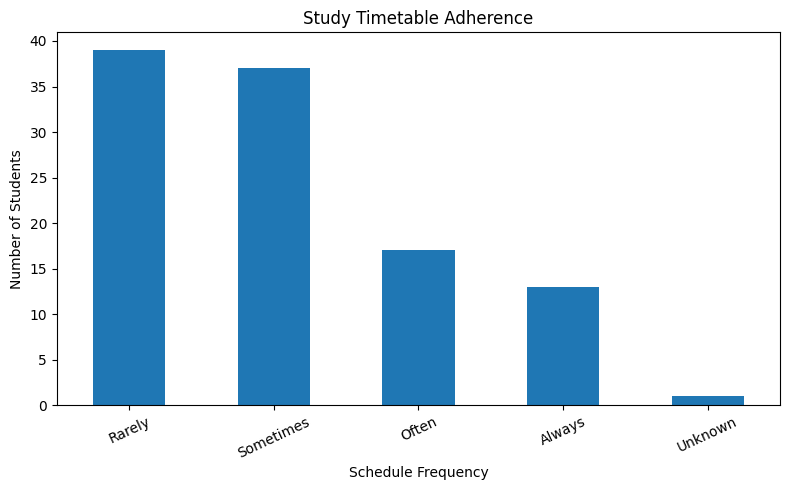

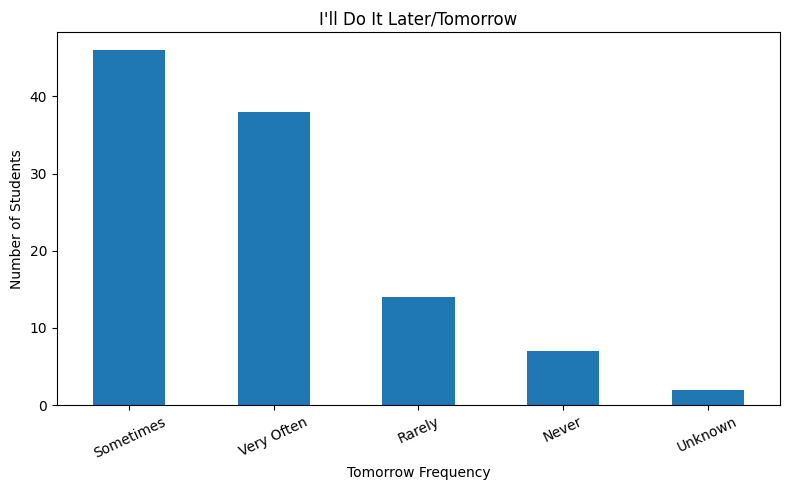

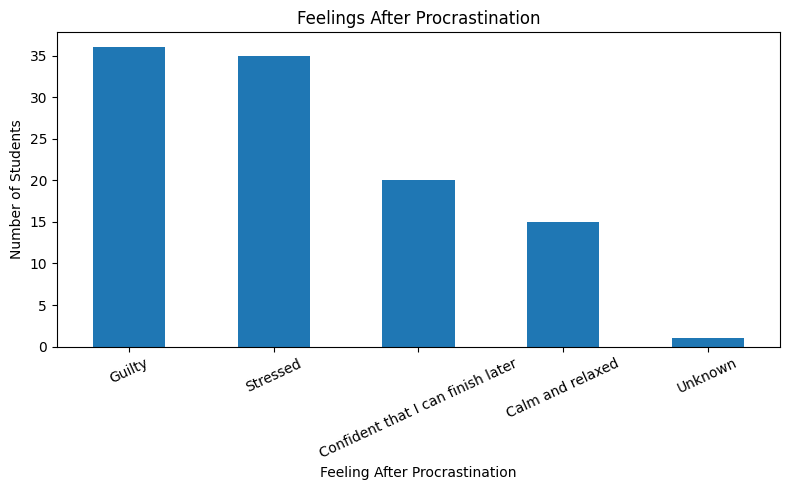

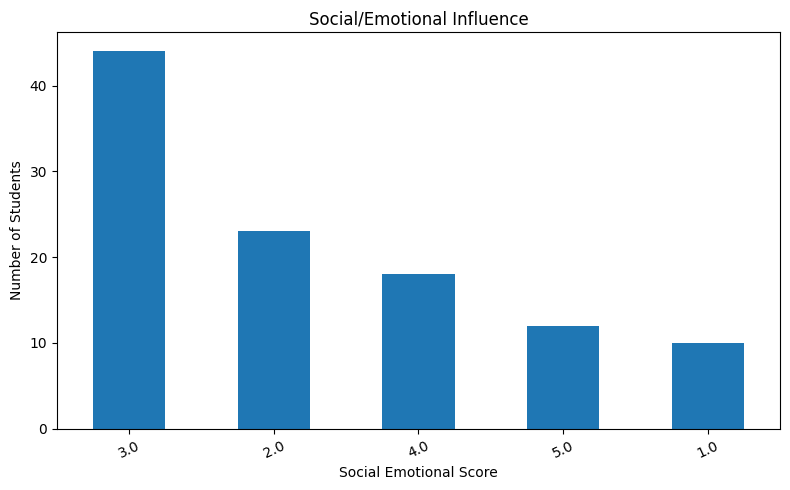

In [ ]:
import matplotlib.pyplot as plt

graph_columns = [
    ("age_group", "Age Group Distribution"),
    ("academic_performance", "Academic Performance"),
    ("phone_usage", "Daily Non-Academic Phone Usage"),
    ("procrastination_time", "Time Lost to Procrastination"),
    ("schedule_frequency", "Study Timetable Adherence"),
    ("tomorrow_frequency", "I'll Do It Later/Tomorrow"),
    ("feeling_after_procrastination", "Feelings After Procrastination"),
    ("social_emotional_score", "Social/Emotional Influence")
]

for col, title in graph_columns:

    plt.figure(figsize=(8,5))

    df[col].value_counts().plot(
        kind="bar"
    )

    plt.title(title)
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Number of Students")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

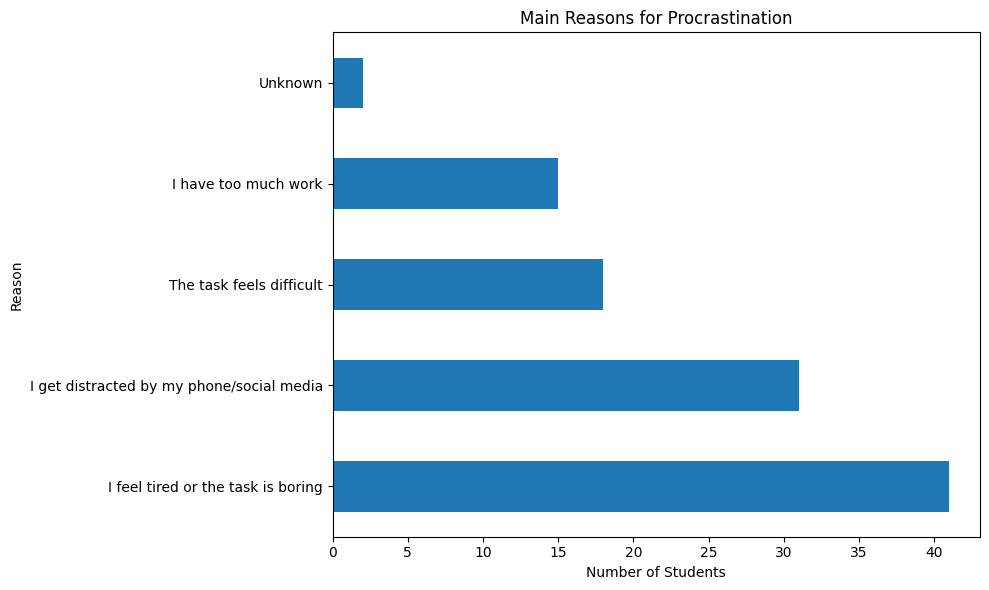

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

df["delay_reason"].value_counts().plot(
    kind="barh"
)

plt.title("Main Reasons for Procrastination")
plt.xlabel("Number of Students")
plt.ylabel("Reason")
plt.tight_layout()

plt.show()

procrastination_time  1-2 hours  3-4 hours  5+hours  Unknown  less than 1 hour
phone_usage                                                                   
1-2 hours                  47.8       21.7      0.0      0.0              30.4
2-4 hours                  51.4       31.4      5.7      0.0              11.4
Less than 1 hour           27.3       18.2      9.1      0.0              45.5
More than 4 hours          16.2       29.7     48.6      0.0               5.4
Unknown                     0.0        0.0      0.0    100.0               0.0


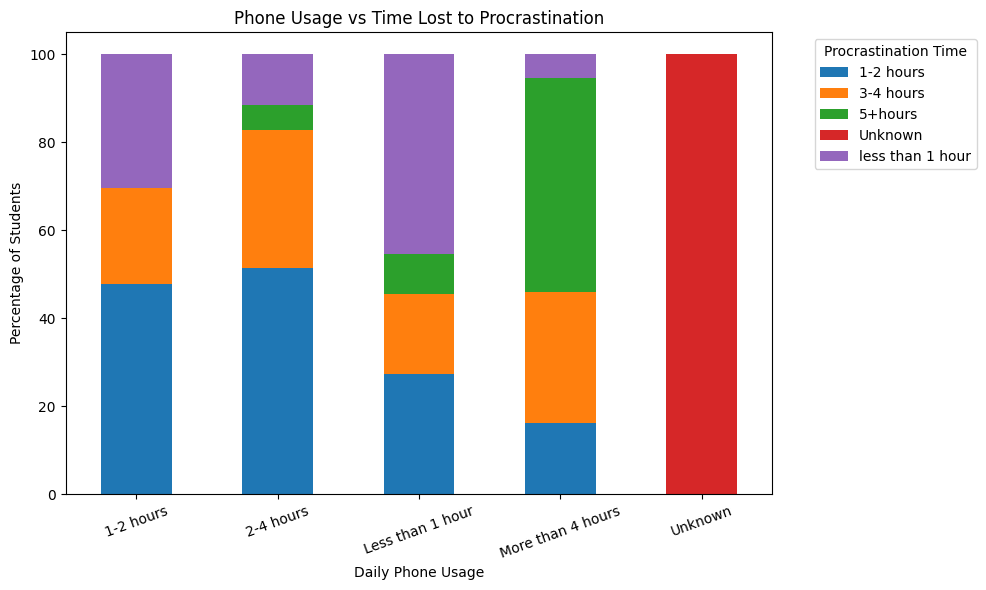

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

phone_vs_procrastination = pd.crosstab(
    df["phone_usage"],
    df["procrastination_time"],
    normalize="index"
) * 100

print(
    phone_vs_procrastination.round(1)
)

phone_vs_procrastination.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title(
    "Phone Usage vs Time Lost to Procrastination"
)

plt.xlabel("Daily Phone Usage")
plt.ylabel("Percentage of Students")
plt.xticks(rotation=20)

plt.legend(
    title="Procrastination Time",
    bbox_to_anchor=(1.05,1)
)

plt.tight_layout()
plt.show()

postpone_duration   1-3 days  I usually start immediately  Less than 1 day  \
schedule_frequency                                                           
Always                   7.7                         46.2             46.2   
Often                   29.4                         17.6             47.1   
Rarely                  38.5                          5.1             28.2   
Sometimes               29.7                         13.5             45.9   
Unknown                  0.0                          0.0              0.0   

postpone_duration   More than 4 days  Unknown  
schedule_frequency                             
Always                           0.0      0.0  
Often                            5.9      0.0  
Rarely                          28.2      0.0  
Sometimes                       10.8      0.0  
Unknown                          0.0    100.0  


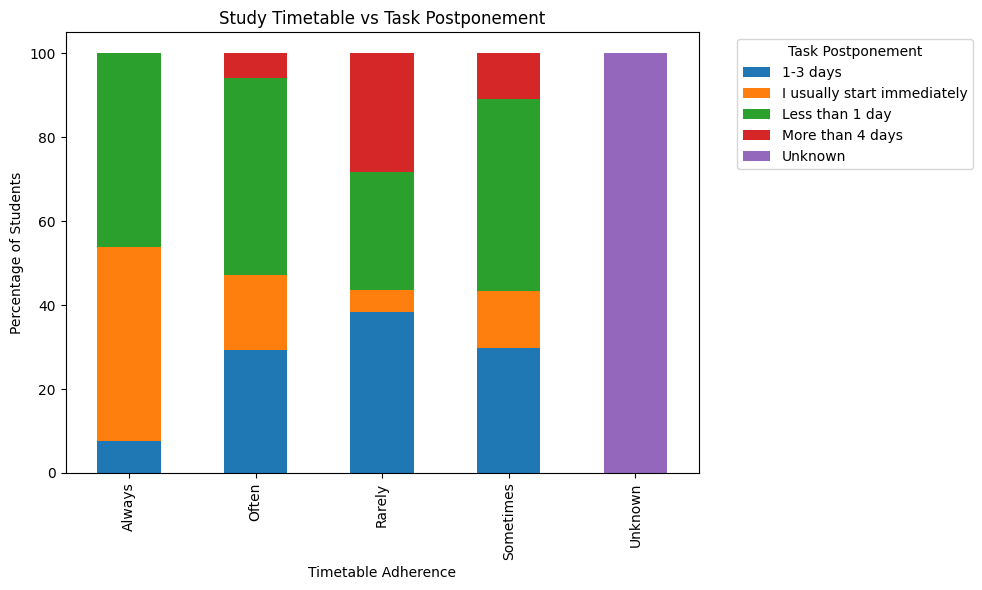

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

schedule_vs_delay = pd.crosstab(
    df["schedule_frequency"],
    df["postpone_duration"],
    normalize="index"
) * 100

print(
    schedule_vs_delay.round(1)
)

schedule_vs_delay.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title(
    "Study Timetable vs Task Postponement"
)

plt.xlabel("Timetable Adherence")
plt.ylabel("Percentage of Students")

plt.legend(
    title="Task Postponement",
    bbox_to_anchor=(1.05,1)
)

plt.tight_layout()
plt.show()

                        age_encoded  cgpa_numeric  phone_hours  \
age_encoded                    1.00         -0.12        -0.15   
cgpa_numeric                  -0.12          1.00         0.15   
phone_hours                   -0.15          0.15         1.00   
procrastination_hours         -0.19          0.03         0.53   
postpone_score                -0.23          0.05         0.42   
exam_delay_score              -0.28         -0.03         0.47   
schedule_score                 0.32         -0.10        -0.35   
tomorrow_score                -0.37          0.22         0.62   
social_emotional_score        -0.23          0.02         0.32   

                        procrastination_hours  postpone_score  \
age_encoded                             -0.19           -0.23   
cgpa_numeric                             0.03            0.05   
phone_hours                              0.53            0.42   
procrastination_hours                    1.00            0.56   
postpone_score

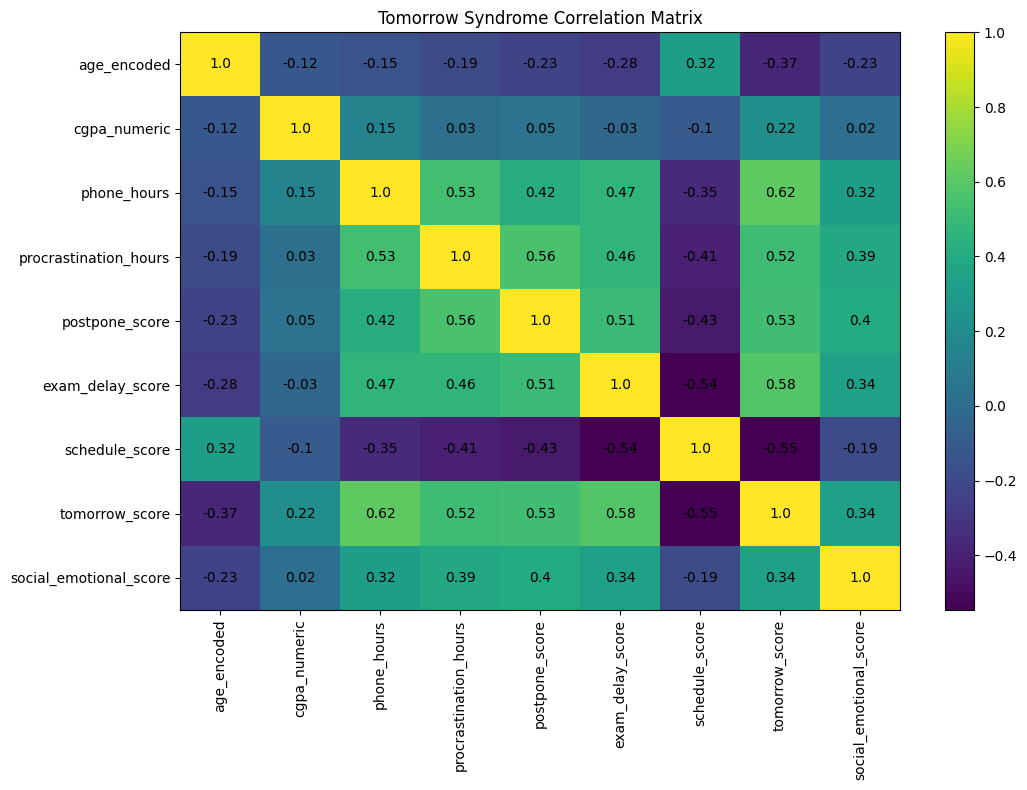

In [ ]:
import matplotlib.pyplot as plt

numeric_columns = [
    "age_encoded",
    "cgpa_numeric",
    "phone_hours",
    "procrastination_hours",
    "postpone_score",
    "exam_delay_score",
    "schedule_score",
    "tomorrow_score",
    "social_emotional_score"
]

correlation = (
    df[numeric_columns]
    .corr()
)

print(correlation.round(2))

plt.figure(figsize=(11,8))

plt.imshow(
    correlation,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):

        plt.text(
            j,
            i,
            round(correlation.iloc[i,j],2),
            ha="center",
            va="center"
        )

plt.title(
    "Tomorrow Syndrome Correlation Matrix"
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

df["high_procrastination"] = (
    df["procrastination_time"]
    .isin([
        "3-4 hours",
        "5+hours"
    ])
    .astype(int)
)

features = [
    "age_encoded",
    "cgpa_numeric",
    "phone_hours",
    "postpone_score",
    "exam_delay_score",
    "schedule_score",
    "tomorrow_score",
    "social_emotional_score",
    "uses_instagram",
    "uses_whatsapp",
    "uses_youtube",
    "uses_other_social"
]

X = df[features].copy()
y = df["high_procrastination"]

for col in X.columns:
    X[col] = X[col].fillna(
        X[col].median()
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTarget distribution:")
print(y.value_counts())

Training samples: 85
Testing samples: 22

Target distribution:
high_procrastination
0    57
1    50
Name: count, dtype: int64


Logistic Regression Accuracy: 77.27 %

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.75      0.78        12
           1       0.73      0.80      0.76        10

    accuracy                           0.77        22
   macro avg       0.77      0.78      0.77        22
weighted avg       0.78      0.77      0.77        22



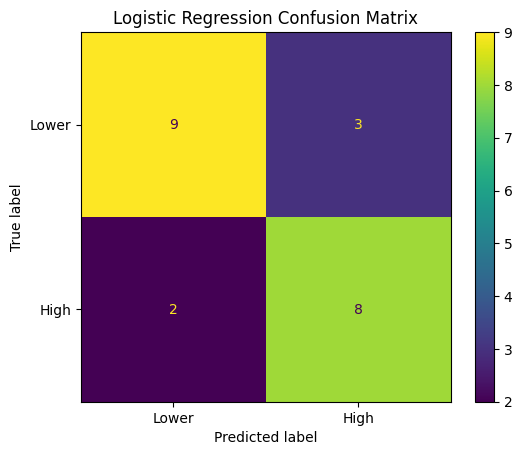

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

scaler_ml = StandardScaler()

X_train_scaled = scaler_ml.fit_transform(
    X_train
)

X_test_scaled = scaler_ml.transform(
    X_test
)

log_model = LogisticRegression(
    random_state=42
)

log_model.fit(
    X_train_scaled,
    y_train
)

y_pred_log = log_model.predict(
    X_test_scaled
)

accuracy = accuracy_score(
    y_test,
    y_pred_log
)

print(
    "Logistic Regression Accuracy:",
    round(accuracy * 100,2),
    "%"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_log
    )
)

cm = confusion_matrix(
    y_test,
    y_pred_log
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Lower",
        "High"
    ]
)

disp.plot()

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

Random Forest Accuracy: 72.73 %

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.75      0.75        12
           1       0.70      0.70      0.70        10

    accuracy                           0.73        22
   macro avg       0.72      0.72      0.72        22
weighted avg       0.73      0.73      0.73        22



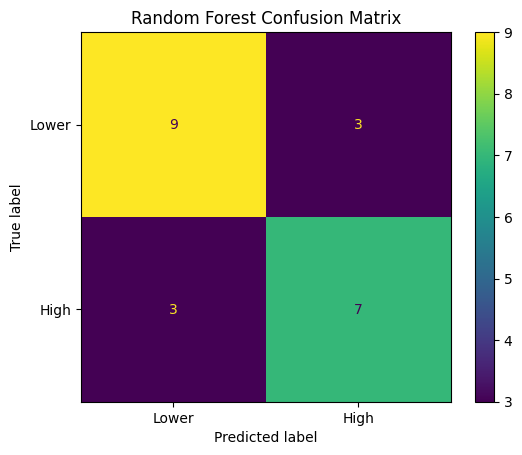

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    round(rf_accuracy * 100,2),
    "%"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=[
        "Lower",
        "High"
    ]
)

disp.plot()

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

                   Feature  Importance
2              phone_hours    0.165223
7   social_emotional_score    0.161690
3           postpone_score    0.152331
4         exam_delay_score    0.124785
6           tomorrow_score    0.105640
5           schedule_score    0.067131
1             cgpa_numeric    0.065712
0              age_encoded    0.059489
10            uses_youtube    0.033248
9            uses_whatsapp    0.026935
8           uses_instagram    0.026155
11       uses_other_social    0.011662


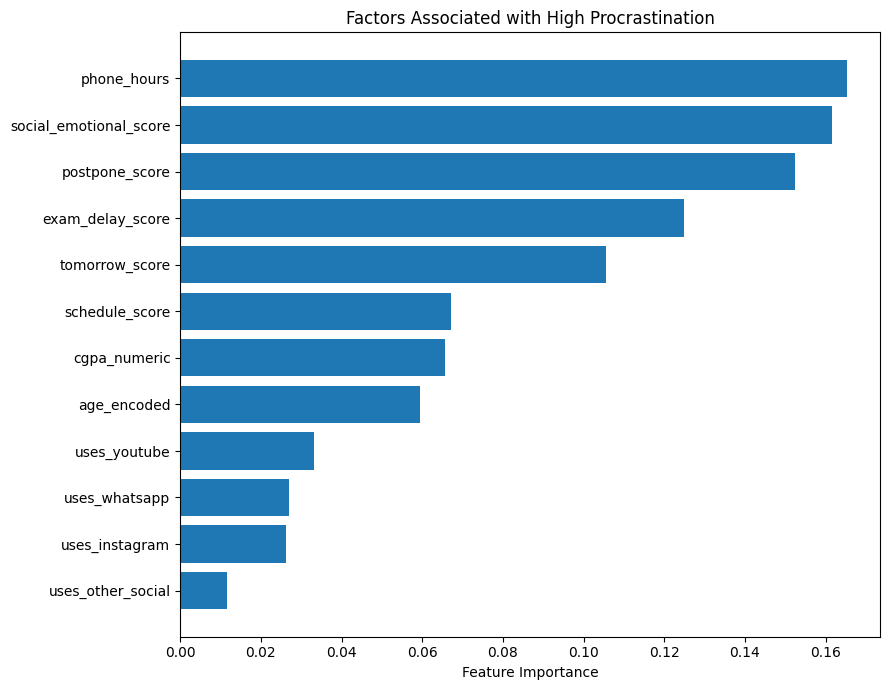

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(9,7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title(
    "Factors Associated with High Procrastination"
)

plt.xlabel("Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
def determine_pattern(row):

    reason = row["delay_reason"]

    if "phone" in reason.lower() or "social media" in reason.lower():
        return "The Scroller"

    elif "difficult" in reason.lower():
        return "The Avoider"

    elif "too much work" in reason.lower():
        return "The Overloaded"

    elif "tired" in reason.lower() or "boring" in reason.lower():
        return "The Tired Starter"

    elif row["tomorrow_score"] >= 3:
        return "The Tomorrow Thinker"

    else:
        return "Mixed Pattern"


df["procrastination_profile"] = df.apply(
    determine_pattern,
    axis=1
)

print(
    df["procrastination_profile"]
    .value_counts()
)

procrastination_profile
The Tired Starter    41
The Scroller         31
The Avoider          18
The Overloaded       15
Mixed Pattern         2
Name: count, dtype: int64


In [ ]:
def generate_recommendation(
    phone_hours,
    schedule_score,
    tomorrow_score,
    social_score,
    postpone_score
):

    recommendations = []

    if phone_hours >= 4:
        recommendations.append(
            "Try a 25-minute phone-free focus session."
        )

    if schedule_score <= 1:
        recommendations.append(
            "Create a simple timetable with only 3 important tasks."
        )

    if tomorrow_score >= 2:
        recommendations.append(
            "Use the 5-minute rule and start the task for only five minutes."
        )

    if social_score >= 4:
        recommendations.append(
            "Reduce social distractions during your planned study period."
        )

    if postpone_score >= 2:
        recommendations.append(
            "Break large tasks into smaller 10-20 minute steps."
        )

    if len(recommendations) == 0:
        recommendations.append(
            "Your current habits look balanced. Keep following your schedule."
        )

    return recommendations


example = generate_recommendation(
    phone_hours=5,
    schedule_score=1,
    tomorrow_score=3,
    social_score=4,
    postpone_score=2
)

for i, recommendation in enumerate(
    example,
    start=1
):
    print(
        f"{i}. {recommendation}"
    )

1. Try a 25-minute phone-free focus session.
2. Create a simple timetable with only 3 important tasks.
3. Use the 5-minute rule and start the task for only five minutes.
4. Reduce social distractions during your planned study period.
5. Break large tasks into smaller 10-20 minute steps.


In [ ]:
df.to_excel(
    "Tomorrow_Syndrome_Cleaned.xlsx",
    index=False
)

df.to_csv(
    "Tomorrow_Syndrome_Cleaned.csv",
    index=False
)

print(
    "Cleaned files saved successfully."
)

Cleaned files saved successfully.


In [ ]:
from google.colab import files

files.download(
    "Tomorrow_Syndrome_Cleaned.xlsx"
)

files.download(
    "Tomorrow_Syndrome_Cleaned.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>